# LogiTrack: Notebook 02: Feature Engineering (Step 7)
Joins the 7 cleaned tables into one **shipment-level analysis table** and derives business features. Outputs:
* `data/cleaned/logitrack_master_features.csv`: full joined table plus features (used by EDA and statistics)
* SQL table `shipment_features` (FK to shipments, deliveries and feedback), which the dashboard view `vw_logitrack` reads.

In [1]:
# --- Setup: make the project root importable and load shared helpers -------------
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from src import utils
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline
from src import feature_engineering as fe
tables = {t: utils.read_cleaned(t) for t in utils.TABLES}
{t: df.shape for t, df in tables.items()}

{'warehouses': (15, 5),
 'drivers': (75, 5),
 'vehicles': (45, 5),
 'routes': (150, 5),
 'shipments': (3000, 8),
 'deliveries': (3000, 5),
 'feedback': (3000, 5)}

### Feature definitions
| Feature | Rule | Business use |
|---|---|---|
| `delivery_hours`, `delivery_days` | `actual_dt − shipment_dt` (NULL if not delivered) | Transit time |
| `is_delayed` | `delay_hours > 0` (NULL for In-Transit/Cancelled) | Delay indicator |
| `is_success` / `is_completed` | status = Delivered / status ∈ {Delivered, Delayed} | Success-rate KPIs |
| `weight_category` | Light < 50 kg ≤ Medium < 500 ≤ Heavy < 1500 ≤ Very Heavy | Load segmentation |
| `distance_category` | Short < 500 km ≤ Medium < 1000 ≤ Long < 1500 ≤ Very Long | Route segmentation |
| `experience_level` | Junior 0-3 y · Mid 4-7 · Senior 8-14 · Expert 15+ | Driver segmentation |
| `delivery_month / day_of_week / hour` | from `actual_dt` | Seasonality |
| `shipment_month / quarter / day_of_week / hour`, `is_weekend` | from `shipment_dt` (available for every order) | Seasonality and dashboard filter |
| `delay_severity` | On-time, Minor ≤ 6 h, Moderate 6-24 h, Severe > 24 h | Delay buckets |
| `capacity_utilization_pct` | `weight_kg / capacity_kg × 100` | Fleet utilisation |
| `speed_kmph` | `distance_km / delivery_hours` | Efficiency |
| `rating_category` | Negative 1-2, Neutral 3, Positive 4-5 | Satisfaction |
| `driver_join_conflict` | `shipment_dt < driver join_date` | Data-quality flag |

Category bins were chosen from the observed distributions: the weight quartiles are about 64, 522 and 1,209 kg, and distances run from 86 to 2,494 km.

In [2]:
master = fe.build_master(tables)
print("Joined shape:", master.shape)
# LEFT joins must not duplicate shipments (1:1:1 relationships)
assert master["shipment_id"].is_unique
master.head(3)

Joined shape: (3000, 32)


,shipment_id,warehouse_id,driver_id,vehicle_id,route_id,shipment_dt,weight_kg,priority,warehouse_name,warehouse_city,warehouse_state,warehouse_capacity,driver_name,driver_experience,driver_rating,driver_join_date,vehicle_type,capacity_kg,fuel_type,vehicle_status,origin_city,dest_city,distance_km,route_type,delivery_id,actual_dt,delivery_status,delay_hours,feedback_id,customer_rating,feedback_comment,feedback_dt
0,1,7,63,35,55,2024-08-30 05:00:00,240.92,Low,Warehouse_7,Pune,Maharashtra,19850,Dinesh Nair,17,4.22,2009-11-16,Truck,2004,Petrol,Active,Hyderabad,Nagpur,1241,Standard,1,2024-08-31 15:04:41,Delivered,6.37,1,3,Okay experience,2024-09-03
1,2,3,49,1,100,2025-02-14 01:00:00,1160.43,Medium,Warehouse_3,Bangalore,Karnataka,8390,Gopal Pillai,2,3.16,2024-04-02,Truck,3986,Petrol,Active,Ahmedabad,Delhi,1065,Standard,2,2025-02-15 07:27:10,Delivered,0.00,2,5,Great experience,2025-02-18
2,3,5,55,40,125,2024-09-28 14:00:00,498.84,High,Warehouse_5,Chennai,Tamil Nadu,14284,Ram Rao,9,3.69,2017-12-10,Van,1140,Diesel,Active,Jaipur,Nagpur,627,Standard,3,2024-09-29 00:47:36,Delivered,4.93,3,3,Okay experience,2024-10-02


In [3]:
features = fe.add_features(master)
print("With features:", features.shape)
features[fe.FEATURE_COLUMNS].head()

With features: (3000, 58)


,shipment_id,delivery_id,feedback_id,delivery_hours,delivery_days,is_completed,is_success,is_cancelled,is_delayed,delay_severity,weight_category,distance_category,experience_level,rating_category,delivery_month,delivery_day_of_week,delivery_hour,shipment_month,shipment_month_name,shipment_quarter,shipment_year,shipment_day_of_week,shipment_hour,is_weekend,capacity_utilization_pct,speed_kmph,feedback_lag_days,driver_join_conflict
0,1,1,1,34.08,1.420,1,1,0,1.0,Moderate (6-24h),Medium,Long,Expert,Neutral,2024-08,Saturday,15.0,2024-08,August,Q3,2024,Friday,5,0,12.02,36.41,3.0,0
1,2,2,2,30.45,1.269,1,1,0,0.0,On-time,Heavy,Long,Junior,Positive,2025-02,Saturday,7.0,2025-02,February,Q1,2025,Friday,1,0,29.11,34.98,3.0,0
2,3,3,3,10.79,0.450,1,1,0,1.0,Minor (<=6h),Medium,Medium,Senior,Neutral,2024-09,Sunday,0.0,2024-09,September,Q3,2024,Saturday,14,1,43.76,58.11,3.0,0
3,4,4,4,36.18,1.508,1,1,0,1.0,Minor (<=6h),Very Heavy,Long,Senior,Neutral,2024-06,Saturday,18.0,2024-06,June,Q2,2024,Friday,6,0,46.19,40.85,3.0,0
4,5,5,5,23.57,0.982,1,0,0,1.0,Severe (>24h),Heavy,Long,Mid,Neutral,2025-07,Thursday,0.0,2025-07,July,Q3,2025,Wednesday,1,0,34.14,42.68,2.0,0


In [4]:
# Sanity checks on the engineered features
checks = {
    "delivery_hours < 0": int((features["delivery_hours"] < 0).sum()),
    "is_delayed null only when not completed": bool((features["is_delayed"].isna() == (features["is_completed"] == 0)).all()),
    "delivery_hours null only when not completed": bool((features["delivery_hours"].isna() == (features["is_completed"] == 0)).all()),
    "capacity_utilization_pct > 100": int((features["capacity_utilization_pct"] > 100).sum()),
    "driver_join_conflict rows": int(features["driver_join_conflict"].sum()),
}
checks

{'delivery_hours < 0': 0,
 'is_delayed null only when not completed': True,
 'delivery_hours null only when not completed': True,
 'capacity_utilization_pct > 100': 0,
 'driver_join_conflict rows': 252}

In [5]:
# Distribution of each categorical feature
for col in ["weight_category", "distance_category", "experience_level", "delay_severity", "rating_category", "shipment_quarter"]:
    print(f"\n{col}:\n{features[col].value_counts(dropna=False).to_string()}")


weight_category:
weight_category
Heavy         963
Medium        805
Light         658
Very Heavy    574

distance_category:
distance_category
Very Long    965
Medium       784
Long         705
Short        546

experience_level:
experience_level
Expert    855
Senior    821
Mid       716
Junior    608

delay_severity:
delay_severity
Minor (<=6h)        1033
On-time              775
Moderate (6-24h)     641
<NA>                 288
Severe (>24h)        263

rating_category:
rating_category
Positive    2118
Neutral      533
Negative     349

shipment_quarter:
shipment_quarter
Q4    780
Q2    770
Q1    733
Q3    717


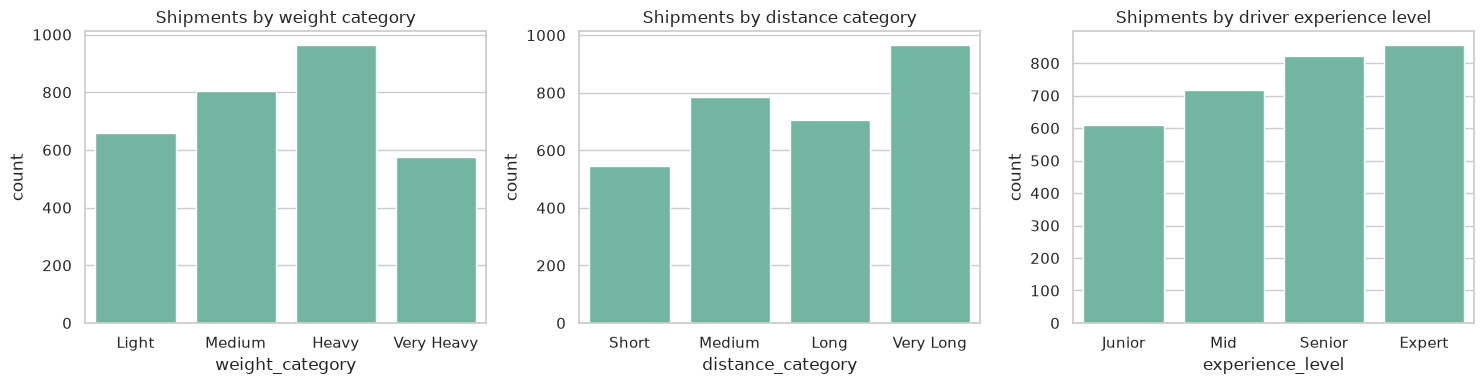

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order_w = fe.WEIGHT_LABELS; order_d = fe.DISTANCE_LABELS; order_e = fe.EXPERIENCE_LABELS
sns.countplot(data=features, x="weight_category", order=order_w, ax=axes[0]).set_title("Shipments by weight category")
sns.countplot(data=features, x="distance_category", order=order_d, ax=axes[1]).set_title("Shipments by distance category")
sns.countplot(data=features, x="experience_level", order=order_e, ax=axes[2]).set_title("Shipments by driver experience level")
plt.tight_layout(); utils.save_fig(fig, "02_feature_categories"); plt.show()

In [7]:
# Quick feature-level KPI preview (completed deliveries only)
done = features[features["is_completed"] == 1]
done.groupby("experience_level", observed=True).agg(
    shipments=("shipment_id", "count"), avg_delay_h=("delay_hours", "mean"),
    delayed_rate=("is_delayed", "mean"), avg_rating=("customer_rating", "mean")).reindex(fe.EXPERIENCE_LABELS).round(3)

,shipments,avg_delay_h,delayed_rate,avg_rating
experience_level,,,,
Junior,549,7.699,0.730,4.067
Mid,654,7.181,0.729,4.046
Senior,738,6.839,0.699,4.108
Expert,771,6.779,0.704,4.154


### Save the feature dataset (CSV and SQL)

In [8]:
out_csv = utils.CLEANED_DIR / "logitrack_master_features.csv"
features.to_csv(out_csv, index=False)
print("Saved", out_csv.name, features.shape)

engine = utils.get_engine()
from sqlalchemy import text
with engine.begin() as conn:
    conn.execute(text("DELETE FROM shipment_features"))     # idempotent re-runs
n = utils.load_table(features[fe.FEATURE_COLUMNS], "shipment_features", engine)
print(f"Loaded {n} rows into shipment_features")
utils.run_query("SELECT COUNT(*) AS rows_in_view, SUM(is_completed) AS completed, ROUND(AVG(delay_hours),2) AS avg_delay FROM vw_logitrack", engine=engine)

Saved logitrack_master_features.csv (3000, 58)


Loaded 3000 rows into shipment_features


,rows_in_view,completed,avg_delay
0,3000,2712,7.08


In [9]:
print("FK violations:", len(utils.run_query("PRAGMA foreign_key_check;", engine=engine)))
utils.run_query("SELECT experience_level, COUNT(*) n FROM shipment_features GROUP BY experience_level", engine=engine)

FK violations: 0


,experience_level,n
0,Expert,855
1,Junior,608
2,Mid,716
3,Senior,821
